# ¡Hola ARIADNA!

Mi nombre es Israel, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

**Es un gusto acompañarte en este proceso, ¡empecemos!**

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt# importar librerías

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código

In [3]:
plans.head()# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Excelente trabajo. Se importaron las librerías necesarias, se cargaron correctamente `plans`, `users` y `usage`, y se revisaron las primeras filas, dimensiones y tipos de datos. Las tablas contienen 2 registros en `plans`, 4,000 en `users` y 40,000 en `usage`

</div>


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos
print(users.isna().mean())# Proporción de valores nulos

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print(usage.isna().sum())
print(usage.isna().mean())# cantidad de nulos para usage

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
Las columnas con datos faltantes en users son:
- city con 11.725% a estos datos los impuaría.
- churn_date con 88.35% a estos los eliminaría.

Las columnas con datos faltantes en usage son:
- date con 0.125% a estos datos los imputaría
- duracion con 55.19% a estos datos los 
- length con 44.74% a estos datos los 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
col_numericas_user = users[['user_id', 'age']].describe()
print(col_numericas_user)# explorar columnas numéricas de users

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna user_id tiene un total de 4.000 usuarios en el dataset. Sus valores van desde el 10.000 hasta el 13.999 y no tiene desviación estandar.  
- La columna age contiene la edad de los usuarios y registra 4.000 datos; pero se evidencia una anomalia: el valor minimo es -999, lo cual indica que hay datos erroneos y debe limpiarse. Tambien las edades de los usuarios estan entre 32 y 79 años con una mediana de 47 años.

In [13]:
col_numericas_usage = usage[['id', 'user_id']].describe()
print(col_numericas_usage)# explorar columnas numéricas de usage

                id       user_id
count  40000.00000  40000.000000
mean   20000.50000  12002.405975
std    11547.14972   1157.279564
min        1.00000  10000.000000
25%    10000.75000  10996.000000
50%    20000.50000  12013.000000
75%    30000.25000  13005.000000
max    40000.00000  13999.000000


- Las columnas id tiene un total de 40.000 registros de uso generados por los usuarios, esta columna identifica de forma unica de 1 a 40.000, 
- Las columnas user_id cuenta con los mismos registros pero conecta cada evento con un usuario registrado. Sus valores se mantienen entre 10.000 y 13.999 los mismos de la tabla users, muestra que los user_id se repiten.

In [14]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']].describe()
print(columnas_user)

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595




- La columna city presenta valores faltantes (nulos), ya que el conteo total de datos es inferior al total de usuarios (4,000). Se registran 7 ciudades distintas, siendo Bogotá la más frecuente con 808 apariciones.
- La columna plan cuenta con los 4.000 datos completos (sin valores ausentes). Registra únicamente 2 tipos de planes, donde el plan básico es el predominante, con una frecuencia de 2,595 usuarios.



In [15]:
# explorar columna categórica de usage
columnas_usage = usage['type'].describe()
print(columnas_usage) # completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object


- La columna type cuenta con los 40.000 datos completos, registra 2 tipos de eventos de comunicacion donde el mas frecuente es el texto o mensaje conun total de 22.092.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- ¿Qué acción tomarías?

Columna age tabla users:
- Sentinel: Se identificó el valor -999, el cual es un valor sentinel utilizado para indicar datos ausentes o errores de registro, ya que no existen edades negativas.
Acción a tomar: Reemplazar los valores -999 por NaN y posteriormente, imputarlos utilizando la mediana de las edades válidas para no distorsionar la distribución de los datos.

Columna city tabla users:
- Sentinel: Presenta un total de 469 datos faltantes (NaN), ya que solo hay 3.531 registros de los 4.000 usuarios totales.
- Acción a tomar: Rellenar las casillas vacías con la categoría 'Unknown' o 'Desconocido'. De esta forma se evita eliminar filas y se mantiene la totalidad de los usuarios para el análisis.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')# completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors='coerce')# completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False))

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64


En reg_date, los registros de usuarios se distribuyen de manera muy uniforme entre los años 2022, 2023 y 2024, con un promedio constante de aproximadamente 1,300 registros por año. Pero se evidencian 40 registros de un año futuro.

In [19]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False))

2024.0    39950
NaN          50
Name: date, dtype: int64


En date, se identificaron 50 registros que resultaron en NaN tras la conversión a formato fecha.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
-
En la columna reg tabla users, aperece un año imposible (2026) con 40 registros causadas por un error de procesamiento. Se podrian tratar como valores nulos para no distorcionar el analisis temporal.

En la columna date tabla usage, los 50 registros clasificados como NaN son fechas imposibles en el momento que fueron transformados a nulos de forma segura (errors='coerce'). La acción a tomar, inspeccionar estos 50 registros para evaluar si se pueden corregir o si se deben omitir del análisis temporal.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Excelente trabajo. Esta sección cumple correctamente con los requerimientos del proyecto y los resultados obtenidos son consistentes con lo esperado.

</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].isna().sum()

40

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# crear función para calcular pct de nulos
def pct_nulos(columna):
    return columna.isna().mean() * 100
    
# Verificación MAR en usage (Missing At Random) para duration  
print(usage.groupby('type')['duration'].agg(pct_nulos))

type
call     0.000000
text    99.927576
Name: duration, dtype: float64


In [24]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')['length'].agg(pct_nulos))

type
call    99.932991
text     0.000000
Name: length, dtype: float64


- Duration: Presenta un 99.93% de nulos en eventos de tipo text y un 0% en call. Esto confirma que los mensajes no registran tiempo de duración.
- Length: Presenta un 99.93% de nulos en eventos de tipo call y un 0% en text. Esto demuestra que las llamadas no registran longitud de texto.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. El reemplazo de los 96 valores `?`, la corrección de las 40 fechas futuras y la verificación MAR están correctamente implementados. Sin embargo, la mediana de `age` debe calcularse directamente con `users['age'].median()`, cuyo resultado es 47, y después reemplazar los 55 valores `-999`. 

</div>


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage[['user_id', 'duration', 'length', 'is_text', 'is_call']].groupby('user_id').sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,duration,length,is_text,is_call
0,10000,23.70,258.0,7,3
1,10001,33.18,226.0,5,10
2,10002,10.74,225.0,5,2


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
}) 
# observar resultado
usage_agg.head(3)

,user_id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas
0,10000,23.70,258.0,7,3
1,10001,33.18,226.0,5,10
2,10002,10.74,225.0,5,2


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(usage_agg, users, on = ['user_id'], how = 'inner')
user_profile.head(5)

,user_id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,23.70,258.0,7,3,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,33.18,226.0,5,10,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,10.74,225.0,5,2,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,8.99,530.0,11,3,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,8.01,229.0,4,3,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['cant_minutos_llamada', 'length', 'cant_mensajes', 'cant_llamadas', 'age']].describe()

,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,age
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,23.317054,288.128032,5.524381,4.478120,48.124531
std,18.168095,180.906841,2.358416,2.144238,17.692032
min,0.000000,0.000000,0.000000,0.000000,18.000000
25%,11.120000,184.000000,4.000000,3.000000,33.000000
50%,19.780000,268.000000,5.000000,4.000000,47.000000
75%,31.415000,361.000000,7.000000,6.000000,63.000000
max,155.690000,2028.000000,17.000000,15.000000,79.000000


In [29]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True)*100)

Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. La agregación calcula correctamente mensajes, llamadas y minutos, pero el cruce se realiza con `how='inner'`, lo que elimina al usuario sin registros de uso y reduce `user_profile` a 3,999 filas.

</div>


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

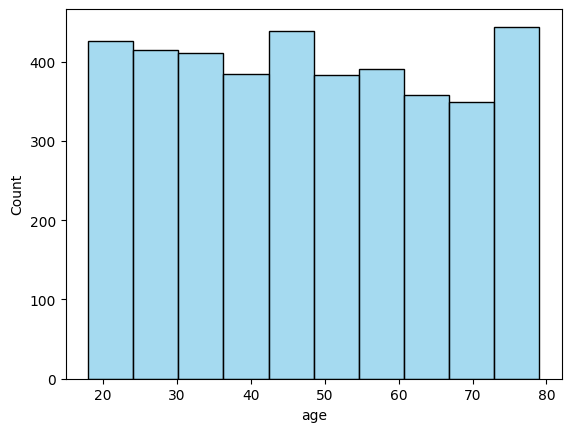

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(user_profile['age'], bins=10, color='skyblue')
plt.show()

💡Insights: 
- Distribución uniforme: La variable age muestra un comportamiento homogéneo en la mayoría de sus rangos entre los 18 y los 70 años, lo que indica una cobertura amplia de usuarios en diferentes etapas de la vida.
- Hay una concentración y pico en adultos mayores (75–79 años) alcanzando uno de los valores más altos de la distribución. Esto sugiere un alto registro en este segmento de edad avanzada.

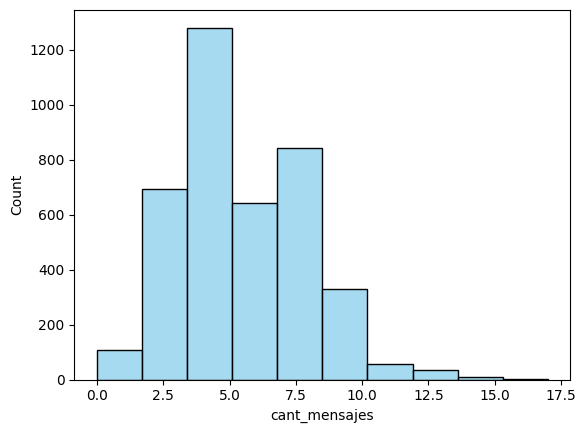

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(user_profile['cant_mensajes'], bins=10, color='skyblue')
plt.show()

💡Insights: 
- Concentración en volúmenes bajos y sesgo a la derecha: La distribución presenta un sesgo a la derecha, mostrando que la gran mayoría de los usuarios envía una cantidad baja a moderada de mensajes.
- El pico principal de consumo: El mayor volumen de usuarios (más de 1,200) se concentra en el rango de 3.5 a 5 mensajes enviados.
- Se observa un segundo pico menor cerca de los 7.5 a 8.5 mensajes, perdiendo presencia casi total a partir de los 10 mensajes.

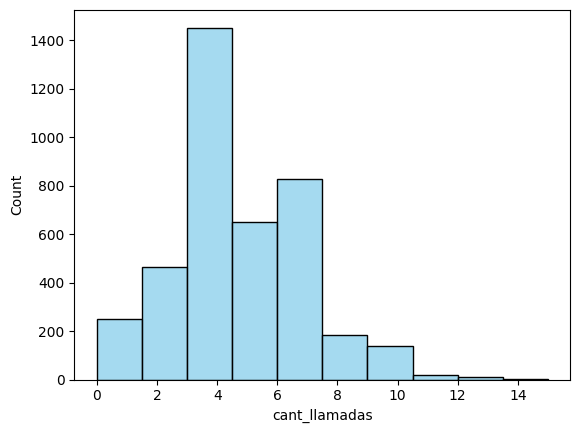

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(user_profile['cant_llamadas'], bins=10, color='skyblue')
plt.show()

💡Insights: 
- Distribución sesgada a la derecha, indicando que la gran mayoría de los usuarios realiza un número moderado de llamadas.
- El pico mas alto esta en el mayor número de usuarios (más de 1,400) se concentra en el rango de 3 a 4.5 llamadas.
- La actividad se mantiene relevante hasta un límite de 7.5 llamadas, punto a partir del cual la frecuencia cae drásticamente.

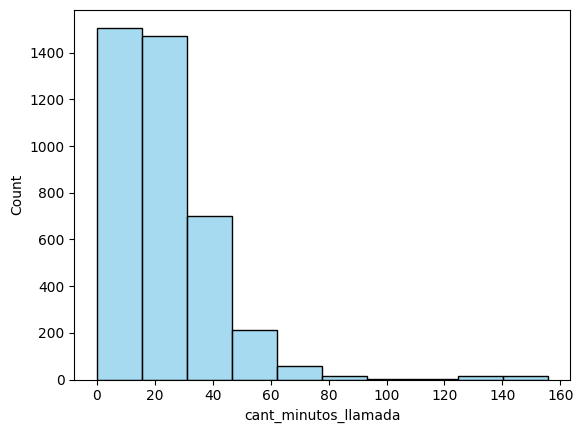

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(user_profile['cant_minutos_llamada'], bins=10, color='skyblue')
plt.show()

💡Insights: 
- Fuerte sesgo a la derecha, lo que refleja que el consumo de tiempo en llamadas se concentra principalmente en rangos cortos.
- Los picos de alto consumo donde la mayor parte de los usuarios se sitúa en los rangos de 0 a 15 minutos y 15 a 30 minutos, sumando más de 1,400 usuarios en cada uno.
-Después de los 30 minutos, la frecuencia de usuarios disminuye drásticamente, dejando una cola larga que llegan hasta los 150 minutos o más.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

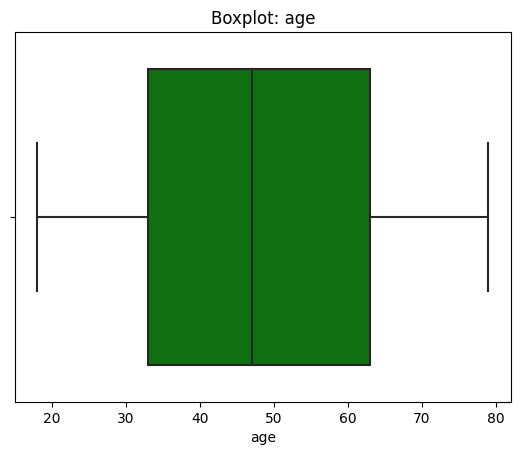

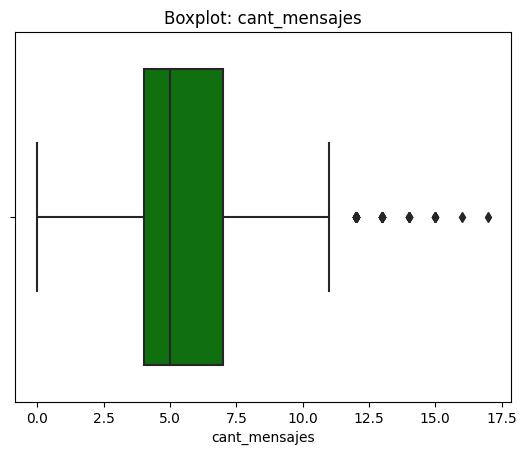

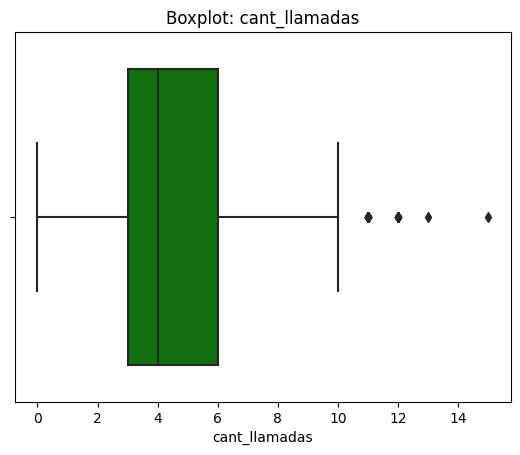

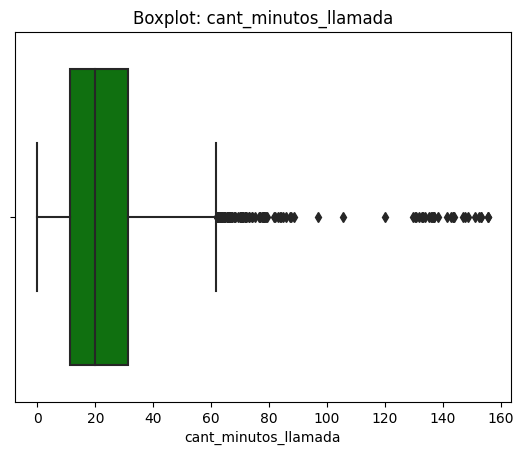

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='green')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: no presenta valores atípicos (outliers), ya que no se observan puntos individuales aislados por fuera de las líneas de los bigotes.
- cant_mensajes: presenta 6 valores atípicos (outliers) superiores, correspondientes a consumos de entre 12 y 17 mensajes.
- cant_llamadas: presenta 4 valores atípicos (outliers) superiores, correspondientes a consumos de entre 11 y 16 llamadas.
- cant_minutos_llamada: presenta una gran cantidad de valores atípicos que inician justo después de los 60 minutos y se extienden hasta casi los 160 minutos.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']


for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    print()
    print(col)
    print('Primer cuartil:', Q1)
    
    Q3 = user_profile[col].quantile(0.75)
    print('Tercer cuartil:', Q3)
    
    IQR = Q3 - Q1
    print('IQR:', IQR)
    
    lower = Q1 - 1.5 * IQR
    print('Limite inferior:', lower)
    
    upper = Q3 + 1.5 * IQR
    print('Limite superior:', upper)


cant_mensajes
Primer cuartil: 4.0
Tercer cuartil: 7.0
IQR: 3.0
Limite inferior: -0.5
Limite superior: 11.5

cant_llamadas
Primer cuartil: 3.0
Tercer cuartil: 6.0
IQR: 3.0
Limite inferior: -1.5
Limite superior: 10.5

cant_minutos_llamada
Primer cuartil: 11.12
Tercer cuartil: 31.415
IQR: 20.295
Limite inferior: -19.322500000000005
Limite superior: 61.8575


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: Se decide mantener, ya que están muy cerca del límite y representan un comportamiento natural de uso sin ser errores de registro. El límite superior es de 11.5 y el valor máximo registrado es 17. 
- cant_llamadas: Se decide mantener ya que reflejan la actividad real de usuarios activos y la diferencia no es extrema. El límite superior es de 10.5 y el máximo de 15.
- cant_minutos_llamada: Aunque el límite es de 61.87 min y el máximo alcanza 155.69 min, se opta por mantener los datos, ya que nn consumo de 2.5 horas es un real en servicios y eliminarlos sesgaría el análisis del consumo real de la red.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Los cuatro histogramas utilizan `hue='plan'`, los cuatro boxplots están presentes, los límites IQR son correctos —11.5 mensajes, 10.5 llamadas y aproximadamente 61.86 minutos— y se comparan con máximos de 17, 15 y 155.69. También es correcta la decisión de conservar los outliers.

</div>


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [39]:
# Crear columna grupo_uso
def clasificar_usuario_uso(row):
    cant_mensajes = row['cant_mensajes']
    cant_llamadas = row['cant_llamadas']
    if cant_llamadas < 5 and cant_mensajes < 5:
        return "Bajo uso"
    elif cant_llamadas < 10 and cant_mensajes < 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile['grupo_uso']= user_profile.apply(clasificar_usuario_uso, axis=1)

In [38]:
# verificar cambios
user_profile.head()

,user_id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,23.70,258.0,7,3,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio
1,10001,33.18,226.0,5,10,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso
2,10002,10.74,225.0,5,2,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio
3,10003,8.99,530.0,11,3,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso
4,10004,8.01,229.0,4,3,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [40]:
# Crear columna grupo_edad
def clasificar_usuario_edad(row):
    edad = row['age']
    if edad < 10:
        return "Joven"
    elif edad < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile['grupo_edad']= user_profile.apply(clasificar_usuario_edad, axis=1)

In [41]:
# verificar cambios
user_profile.head()

,user_id,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,23.70,258.0,7,3,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio,Adulto
1,10001,33.18,226.0,5,10,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso,Adulto
2,10002,10.74,225.0,5,2,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio,Adulto
3,10003,8.99,530.0,11,3,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso,Adulto Mayor
4,10004,8.01,229.0,4,3,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

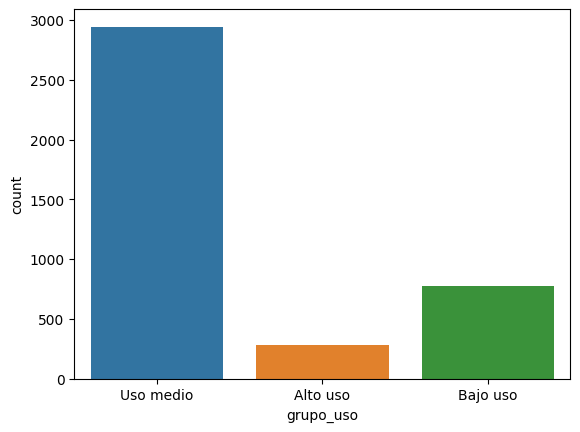

In [42]:
# Visualización de los segmentos por uso
sns.countplot(user_profile['grupo_uso'])

plt.show()

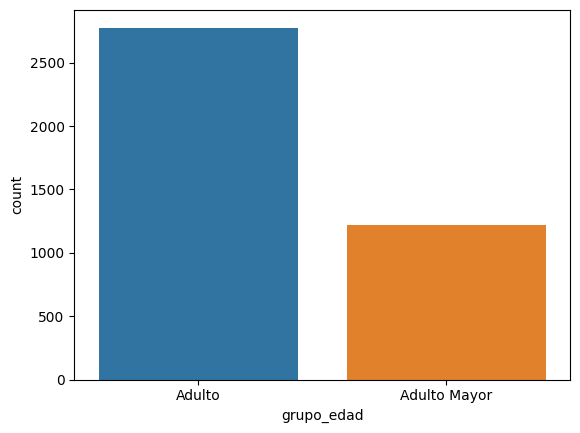

In [43]:
# Visualización de los segmentos por edad
sns.countplot(user_profile['grupo_edad'])

plt.show()

 <div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Las reglas de segmentación por uso y edad están correctamente implementadas, y ambos countplots incluyen títulos y etiquetas. Sin embargo, la segmentación se ejecuta sobre 3,999 usuarios porque el `inner merge` del Paso 4 eliminó al usuario sin actividad.

</div>



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Dataset users:
churn_date: Presentaba un 88.35% de datos faltantes. Dado que supera el umbral crítico (>80-90%), esta columna se ignoro para la segmentación. 
city: Presentaba un 11.725% de valores nulos por lo que se procedió a su investigación y se reemplazo por valores nulos NA.

- Dataset usage:
duracion: 55.19% de valores nulos, correspondientes a registros donde no se realizaron llamadas de voz.
length: 44.74% de datos nulos, asociados a registros de llamadas sin tráfico de texto.
date: Un porcentaje insignificante del 0.125% de nulos, imputable por ser menor al 5%.


🔍 **Segmentos por Edad**
- Comportamiento por Edad: La edad de los usuarios muestra una distribución uniforme entre los 18 y 79 años (350–400 usuarios por rango), con un incremento marcado en el segmento adulto mayor de 75 a 79 años.
- Adultos: Representan el grupo principal con casi 2,800 usuarios.
- Adulto Mayor: Constituye una porción significativa de casi 1,200 usuarios, confirmando que la población de mayor edad mantiene un consumo activo y constante en ConnectaTel.


📊 **Segmentos por Nivel de Uso**
- Uso medio representa la gran mayoría de la base de datos, superando los 2,900 usuarios.
- Bajo uso es el segundo grupo con casi 800 usuarios.
- Alto uso es el grupo más reducido con cerca de 300 usuarios.

➡️ Esto sugiere que la mayor parte de los clientes (un 73%) consume lo normal y se acomoda bien al plan medio. También vemos un 20% de usuarios que casi no usan el servicio y podrían estar aprovechándolo mejor. Por último, el grupo de alto uso es pequeño (solo el 7%), pero son los clientes que más consumen y los que más valor le generan a la empresa.


💡 **Recomendaciones**
- Para los de 'Uso Medio' (73%): Crear promociones simples con minutos o datos extra para ver si se animan a pasarse a un plan más alto.
- Para los de 'Bajo Uso' (20%): Ofrecer paquetes más económicos o flexibles para motivarlos a consumir más y evitar que cancelen el servicio.
- Para los de 'Alto Uso' (7%) y Adultos Mayores (30%): Diseñar un plan especial con bastante tiempo en llamadas para no perder a estos clientes intensivos, y mantener planes sencillos y claros para la población mayor.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.


---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

In [2]:
[GitHub](https://github.com/AriadnaParra/sprint7-final-project/blob/9cac3c89efa9aa1c9d9ffbf6f8b876c1a712677f/S7%20Version-Estudiante-Project-ConnectaTel.ipynb)

SyntaxError: invalid syntax (413591380.py, line 1)

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Felicitaciones, los hallazgos son claros y directos. Esto es muy importante
para cualquier analista de datos, ya que no alcanza solo con obtener números, también debemos ser
capaces de comunicar cómo esos números impactan en el negocio.

Felicitaciones por el trabajo realizado. Si bien hay algunos puntos de mejora, el proyecto está en
condiciones de ser aprobado.

¡Mucho éxito en tu camino dentro del mundo de los datos!


</div>

